# DataWorth KZ — зерттеу notebook-ы
Деректер: UCI Default of Credit Card Clients (Тайвань, 2005). **Қазақстан деректері емес.**

Бұл notebook барлық нәтижелерді қайта шығарады. Толық оқыту ~3 минут алады; `RETRAIN = False` болса, сақталған нәтижелер оқылады.

In [1]:
RETRAIN = False
import json, numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 200)

## 1. Деректерді жүктеу және тексеру

In [2]:
from data_loader import load, integrity_check, FEATURE_SETS
df = load()
print(df.shape)
integrity_check(df)

(30000, 25)


{'n_rows': 30000,
 'n_default': 6636,
 'limit_bal_mean': 167484.32,
 'matches_reference': True}

## 2. EDA

In [3]:
import eda
if RETRAIN: eda.main()
e = json.load(open('results/eda.json'))
print('Дефолт үлесі:', e['default_rate'], '| жетіспейтін мәндер:', e['missing_values_total'])
pd.DataFrame(e['default_rate_by_PAY_0']).T

Дефолт үлесі: 0.2212 | жетіспейтін мәндер: 0


,n,default_rate
-2,2759.0,0.1323
-1,5686.0,0.1678
0,14737.0,0.1281
1,3688.0,0.3395
2,2667.0,0.6914
3,322.0,0.7578
4,76.0,0.6842
5,26.0,0.5000
6,11.0,0.5455
7,9.0,0.7778


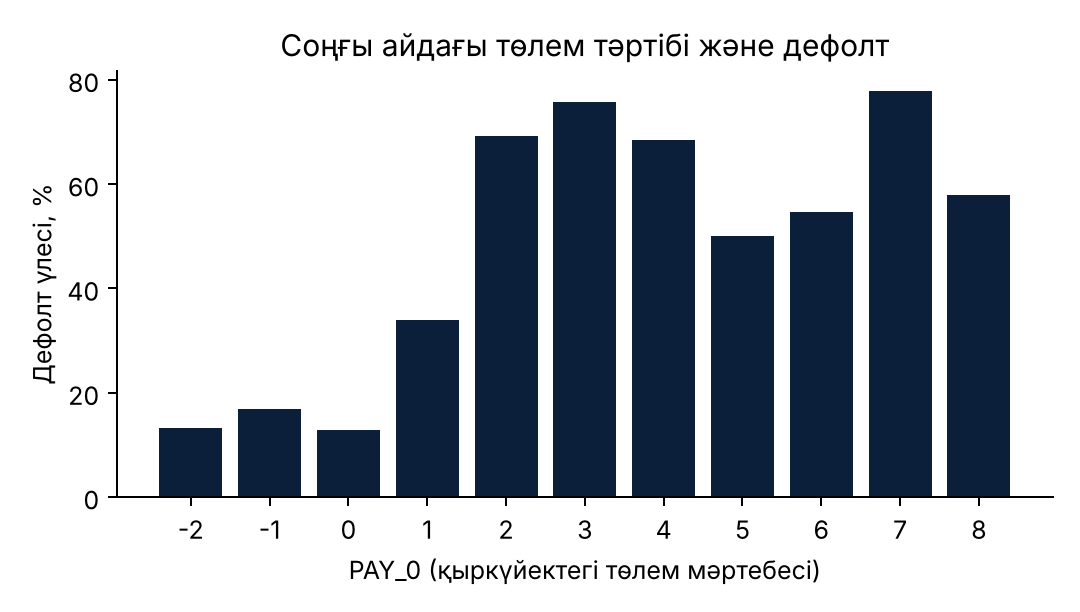

In [4]:
display(Image('figures/eda_pay0_default.png', width=600))

## 3. Model A / B / C × 3 алгоритм (70/15/15, seed 42)

In [5]:
import model_training
if RETRAIN: model_training.main()
mc = pd.read_csv('results/model_comparison.csv')
mc[['model','n_features','roc_auc','roc_auc_ci_lo','roc_auc_ci_hi','pr_auc','brier','precision','recall','f1']].round(4)

,model,n_features,roc_auc,roc_auc_ci_lo,roc_auc_ci_hi,pr_auc,brier,precision,recall,f1
0,A_LogReg,2,0.7080,0.6870,0.7289,0.4822,0.1486,0.5025,0.5040,0.5033
1,A_RandomForest,2,0.7320,0.7143,0.7517,0.4935,0.1415,0.4804,0.5161,0.4976
2,A_GradBoost,2,0.7320,0.7137,0.7518,0.5036,0.1416,0.4576,0.5532,0.5009
3,B_LogReg,6,0.7110,0.6895,0.7320,0.4859,0.1478,0.4880,0.5120,0.4998
4,B_RandomForest,6,0.7704,0.7524,0.7885,0.5421,0.1364,0.4808,0.5894,0.5295
5,B_GradBoost,6,0.7714,0.7537,0.7891,0.5315,0.1366,0.4991,0.5703,0.5323
6,C_LogReg,19,0.7114,0.6908,0.7320,0.4906,0.1473,0.5059,0.5201,0.5129
7,C_RandomForest,19,0.7812,0.7631,0.7981,0.5562,0.1350,0.5429,0.5532,0.5480
8,C_GradBoost,19,0.7774,0.7593,0.7943,0.5454,0.1361,0.5060,0.5974,0.5479


In [6]:
pd.read_csv('results/paired_differences.csv').round(4)

,type,algo,comparison,metric,diff,ci_lo,ci_hi,p_le_0
0,information_effect,LogReg,B-A,roc_auc,0.0031,-0.0027,0.0089,0.154
1,information_effect,LogReg,B-A,pr_auc,0.0040,-0.0048,0.0127,0.197
2,information_effect,LogReg,C-B,roc_auc,0.0004,-0.0038,0.0040,0.407
3,information_effect,LogReg,C-B,pr_auc,0.0047,0.0007,0.0085,0.011
4,information_effect,LogReg,C-A,roc_auc,0.0035,-0.0033,0.0100,0.156
5,information_effect,LogReg,C-A,pr_auc,0.0086,-0.0015,0.0180,0.042
6,information_effect,RandomForest,B-A,roc_auc,0.0384,0.0279,0.0484,0.000
7,information_effect,RandomForest,B-A,pr_auc,0.0482,0.0306,0.0652,0.000
8,information_effect,RandomForest,C-B,roc_auc,0.0107,0.0038,0.0176,0.002
9,information_effect,RandomForest,C-B,pr_auc,0.0141,0.0031,0.0257,0.012


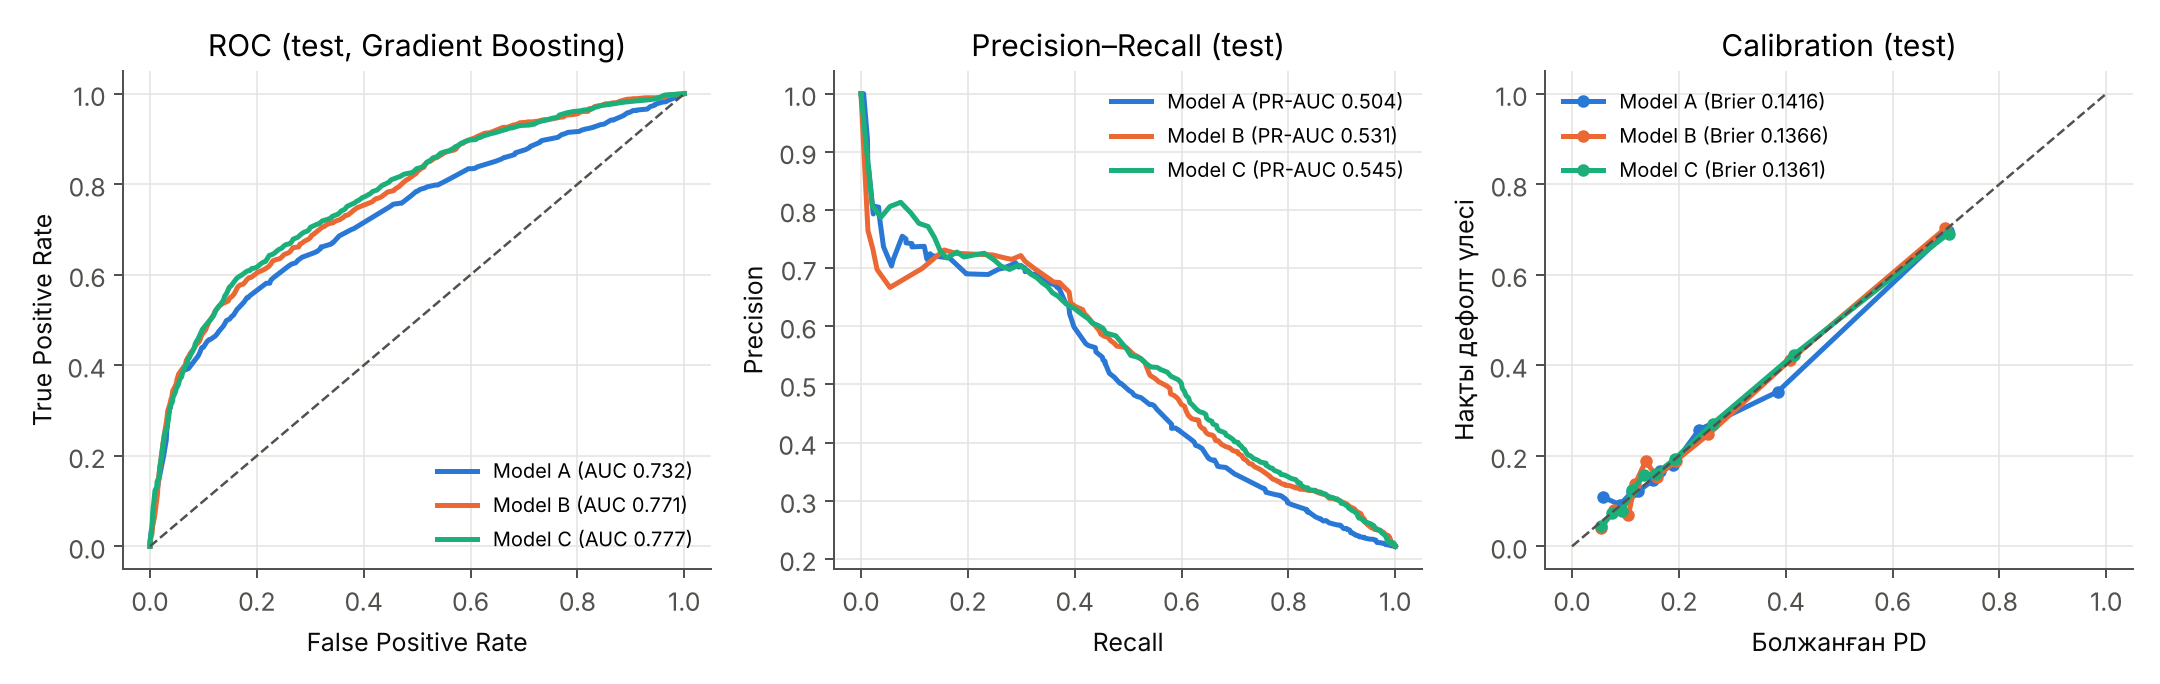

In [7]:
display(Image('figures/roc_pr_calibration.png'))

## 4. Data Value Frontier
$V(S)=\Pi(S)-\Pi(S_0)-C(S)$; шешім: PD < t болса лимитті жалғастыру; дефолтсыз: $+m\cdot EAD$, дефолт: $-LGD\cdot EAD$.

In [8]:
import dvf_experiment
if RETRAIN: dvf_experiment.main()
from dvf_live import evaluate_subsets, optimal_subset, frontier
from financial_engine import FinParams
t = evaluate_subsets(FinParams(margin=0.10, lgd=0.75))
print('Оңтайлы жиынтық:', optimal_subset(t).subset)
frontier(t)

Оңтайлы жиынтық: G1+G2+G3


,max_fields,subset,test_net_value_pc,val_net_value_pc
0,2,S0,0.000000,0.000000
1,3,G2,627.793011,641.133844
2,4,G2,627.793011,641.133844
3,5,G1+G2,1025.205783,679.537544
4,6,G1+G2+G3,1813.801011,927.426344
5,7,G1+G2+G3,1813.801011,927.426344
6,8,G1+G2+G3,1813.801011,927.426344
7,9,G1+G2+G3,1813.801011,927.426344
8,10,G1+G2+G3,1813.801011,927.426344
9,11,G1+G2+G3,1813.801011,927.426344


In [9]:
for cost in (0, 5, 10, 20, 50):
    o = optimal_subset(evaluate_subsets(FinParams(data_cost_bp=cost)))
    print(f'деректер тобының құны {cost:>3} б.п. → {o.subset:10s} ({int(o.n_fields)} өріс), test V = {o.test_net_value_pc:,.0f} NT$/кл')

деректер тобының құны   0 б.п. → G1+G2+G3   (6 өріс), test V = 1,814 NT$/кл
деректер тобының құны   5 б.п. → G1+G2+G3   (6 өріс), test V = 1,648 NT$/кл
деректер тобының құны  10 б.п. → G1+G2+G3   (6 өріс), test V = 1,482 NT$/кл
деректер тобының құны  20 б.п. → G2         (3 өріс), test V = 407 NT$/кл
деректер тобының құны  50 б.п. → G2         (3 өріс), test V = 75 NT$/кл


In [10]:
json.load(open('results/dvf_summary.json'))['profit_diff_bootstrap_base']

{'GradBoost_B-A': {'mean_per_client': 1926.0357833333335,
  'ci_lo': 1216.2302448611113,
  'ci_hi': 2712.3730968055547,
  'p_le_0': 0.0},
 'GradBoost_C-B': {'mean_per_client': -482.4041500000001,
  'ci_lo': -1024.9279140277777,
  'ci_hi': 50.32177930555541,
  'p_le_0': 0.96},
 'GradBoost_C-A': {'mean_per_client': 1443.6316333333332,
  'ci_lo': 805.5001073611112,
  'ci_hi': 2133.3934293055554,
  'p_le_0': 0.0},
 'RandomForest_B-A': {'mean_per_client': 1145.8313833333332,
  'ci_lo': 503.92979777777765,
  'ci_hi': 1874.122365833333,
  'p_le_0': 0.001},
 'RandomForest_C-B': {'mean_per_client': 322.38728333333336,
  'ci_lo': -108.75470486111107,
  'ci_hi': 727.2318673611111,
  'p_le_0': 0.074},
 'RandomForest_C-A': {'mean_per_client': 1468.2186666666664,
  'ci_lo': 732.8958805555554,
  'ci_hi': 2208.647414027777,
  'p_le_0': 0.0},
 'LogReg_B-A': {'mean_per_client': -325.53366111111114,
  'ci_lo': -791.3211119444444,
  'ci_hi': 95.24915347222186,
  'p_le_0': 0.93},
 'LogReg_C-B': {'mean_per_

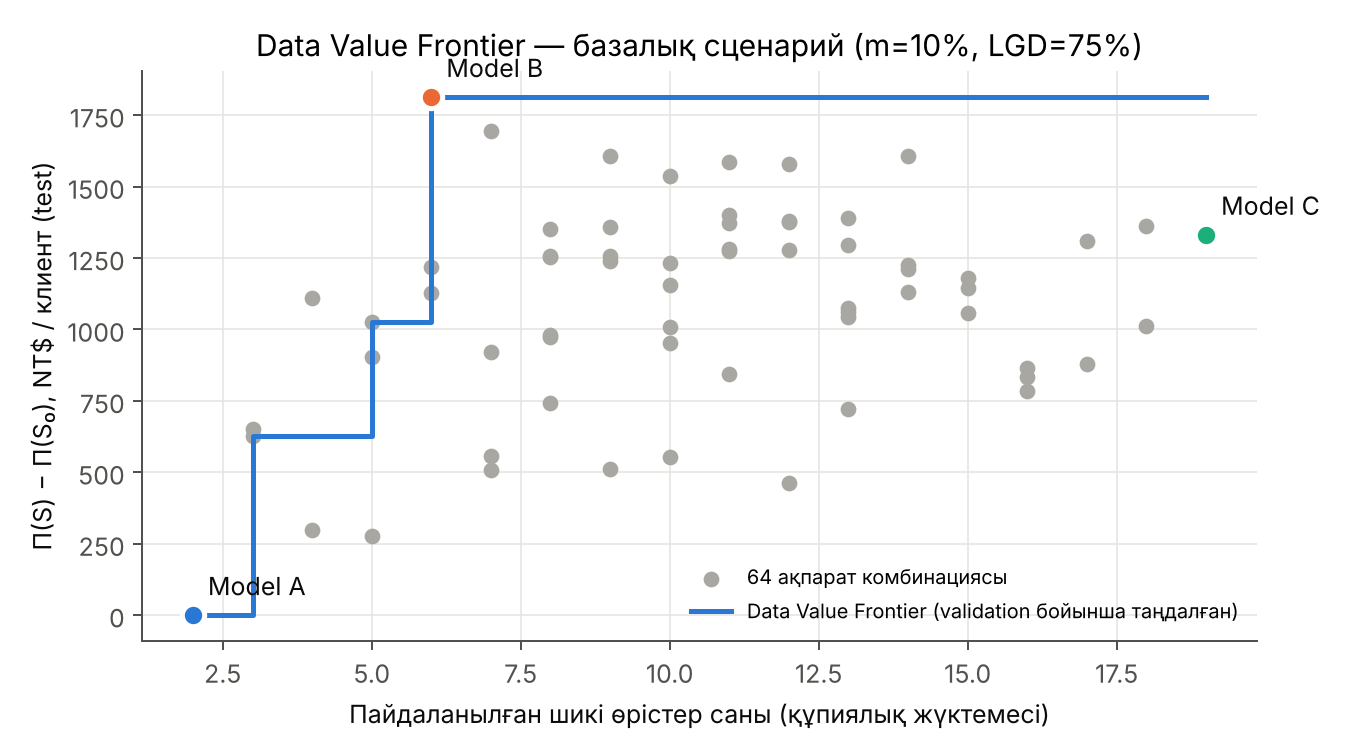

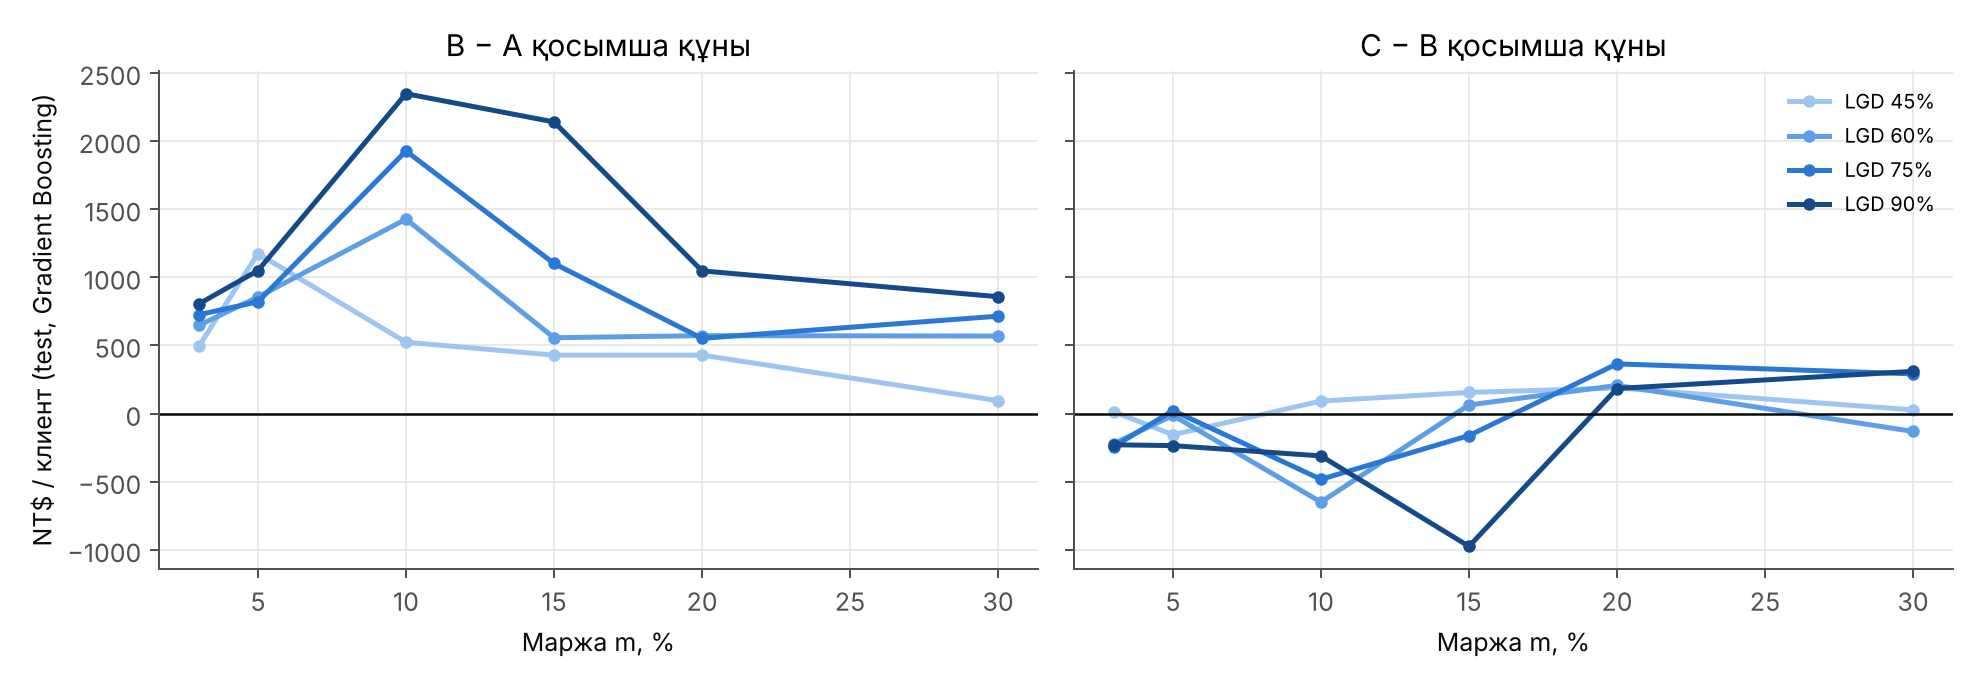

In [11]:
display(Image('figures/dvf_frontier.png', width=700)); display(Image('figures/sensitivity.png'))

## 5. Орнықтылық: Logistic Regression one-hot

In [12]:
json.load(open('results/robustness_logreg_ohe.json'))

{'A': {'C': 0.1,
  'val_roc_auc': 0.7425798034394513,
  'test_roc_auc': 0.7312046416258642,
  'test_pr_auc': 0.4902621661893701},
 'B': {'C': 0.1,
  'val_roc_auc': 0.7640222510555631,
  'test_roc_auc': 0.7531249426931471,
  'test_pr_auc': 0.5096879967762148},
 'C': {'C': 0.01,
  'val_roc_auc': 0.7652206825855382,
  'test_roc_auc': 0.7578811249564468,
  'test_pr_auc': 0.5237444137848266}}

## 6. Қорытынды
- A → B: экономикалық пайда маңызды және барлық сценарийде оң (H2).
- B → C: AUC шамалы өседі, бірақ модельдік пайда айырмасы маңызды емес (H1, шартты).
- Ақпарат құны алгоритм мен кодтауға тәуелді (H3).

Шектеулер: шетелдік деректер, 2005 жыл, ақшалай параметрлер — болжам.